# Mathematics: Numerical Linear Algebra

> **Who is this for:** a beginner who has finished [`01_linear_algebra.ipynb`](01_linear_algebra.ipynb) and [`09_numerical_methods.ipynb`](09_numerical_methods.ipynb), or a university student revising *Numerical Computing*, *Numerical Linear Algebra* or *Scientific Computing* (BS core / MS elective) for an exam or interview.
>
> **What you will learn**
> - **Gaussian elimination with partial pivoting** and the **LU decomposition** $PA = LU$, from scratch; its $\tfrac23 n^3$ cost and why you factor once and solve many times
> - **Cholesky** ($A = LL^\top$) for symmetric positive definite matrices such as covariance and Gaussian-process kernel matrices, and the "jitter" trick
> - **QR**: classical vs modified Gram–Schmidt vs **Householder**, and their very different numerical stability; QR for least squares
> - **Conditioning** and **backward error**, and why the **normal equations square the condition number**
> - **Iterative solvers**: Jacobi, Gauss–Seidel and **conjugate gradient (CG)** from scratch; convergence versus condition number; **preconditioning**
> - **Eigenvalue algorithms**: power iteration, inverse iteration, Rayleigh quotient iteration, **PageRank**, and the QR algorithm
> - **Sparse matrices**: the **CSR** format from scratch, `scipy.sparse`, `cg`, `eigsh`, and memory savings
> - **Randomized linear algebra**: randomized SVD and sketch-and-solve least squares
> - AI links: ridge regression via Cholesky vs CG, Gaussian-process cost, and **LoRA as a truncated SVD**
>
> **Prerequisites:** [`01_linear_algebra.ipynb`](01_linear_algebra.ipynb) (matrices, eigenvalues, SVD), [`09_numerical_methods.ipynb`](09_numerical_methods.ipynb) (floating point, error, convergence order) and [`08_industry_math_in_practice.ipynb`](08_industry_math_in_practice.ipynb) (`solve` vs `inv`, condition numbers). Helpful: [`00_AI_Fundamentals/dsa/07_graphs.ipynb`](../00_AI_Fundamentals/dsa/07_graphs.ipynb) (for PageRank).
>
> **Time needed:** about 3 to 4 hours (reading, running, and the practice problems).
>
> **Runs on:** CPU, no API key, no internet. Libraries: numpy, scipy, pandas, matplotlib, networkx, scikit-learn. The whole notebook runs in about a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Trefethen and Bau, *Numerical Linear Algebra* (SIAM, 1997; 25th-anniversary edition 2022), and Golub and Van Loan, *Matrix Computations* (4th ed., 2013).

## Explained simply

Almost every machine-learning model ends up as a big table of numbers (a matrix) and a question like "which numbers $x$ make $Ax = b$ true?" or "what are the main directions in this data?". With 3 unknowns you can solve that by hand; with 3 million you need clever recipes that are fast, use little memory, and do not let rounding errors grow. Numerical linear algebra is that set of recipes. The big ideas are: **break a hard matrix into easy pieces once** and reuse them, **guess and improve** when the matrix is too big to break, and **skip the zeros** when most entries are zero.

**Everyday examples**
- Solving a Sudoku-like system of equations, such as "3 apples and 2 pears cost 7, 1 apple and 4 pears cost 9", is a tiny $Ax = b$; a supermarket's pricing model has thousands of such equations.
- Google's original **PageRank** treats the web as a huge matrix and finds its main "direction", which ranks pages by importance.
- A road map stored as "which town connects to which" is mostly empty (each town touches only a few others). Storing only the roads, not every possible pair, is a **sparse matrix**.

**A tiny concrete example.** Solve $2x + y = 5$, $4x + 5y = 13$. Subtract 2 × the first equation from the second: $3y = 3$, so $y = 1$, then $2x + 1 = 5$ gives $x = 2$. Writing down the "2 ×" you used is exactly the **L** in an LU decomposition, and the simplified equations are the **U**. Next time the right-hand side changes, you reuse L and U and skip the elimination.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| LU / Cholesky / QR | Break a matrix into simple triangular or orthogonal pieces once, reuse many times | Linear regression, Gaussian processes, Kalman filters, simulations |
| Conjugate gradient | Guess the answer and improve it using only matrix-times-vector products | Huge sparse systems, Hessian-free optimisation, physics engines |
| Low-rank / randomized SVD | Keep only the few directions that matter most | PCA, recommender systems, LoRA fine-tuning, compression |

### How this notebook is different from its neighbours
- [`01_linear_algebra.ipynb`](01_linear_algebra.ipynb) teaches *what* matrices, eigenvalues and the SVD are. Here we learn *how a computer actually computes them*, accurately and fast.
- [`08_industry_math_in_practice.ipynb`](08_industry_math_in_practice.ipynb) gives the production rule "use `solve`, not `inv`". This notebook explains what `solve` does inside (LU with pivoting), and covers factorisations, iterative and sparse solvers that notebook does not.
- Convex optimisation and duality build on these solvers in [`12_convex_optimization_and_duality.ipynb`](12_convex_optimization_and_duality.ipynb).

## Table of contents
1. Gaussian elimination, pivoting and LU
2. Cholesky factorisation
3. QR factorisation and least squares
4. Conditioning and backward error
5. Iterative solvers: Jacobi, Gauss–Seidel, conjugate gradient
6. Eigenvalue algorithms and PageRank
7. Sparse matrices
8. Randomized linear algebra
9. Summary table
10. How this connects to modern AI
11. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)
rng = np.random.default_rng(42)   # the modern NumPy random generator

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import scipy
import scipy.linalg as sla
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import networkx as nx
try:                                   # keep the linear-algebra library (BLAS) to 2 threads, so timings
    from threadpoolctl import threadpool_limits   # are stable on a shared or busy machine
    threadpool_limits(2)
except ImportError:
    pass
print("scipy", scipy.__version__, "| networkx", nx.__version__)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


scipy 1.18.0 | networkx 3.7


---
## 1. Gaussian elimination, pivoting and LU

> **In plain English:** solve equations by eliminating one unknown at a time, always using the biggest available number as the pivot so rounding errors stay small, and record the steps so they can be reused.

**Gaussian elimination** turns $Ax = b$ into an upper-triangular system $Ux = c$ by subtracting multiples of one row from the rows below it; then **back substitution** solves for $x_n, x_{n-1}, \dots, x_1$.

**LU decomposition.** If we store the multipliers $\ell_{ij}$ in a unit lower-triangular matrix $L$, we get $A = LU$. With row swaps (a permutation matrix $P$), every non-singular matrix has a factorisation

$$PA = LU.$$

To solve $Ax = b$: solve $Ly = Pb$ (**forward substitution**), then $Ux = y$ (back substitution). Each triangular solve costs $n^2$ flops, while the factorisation costs $\tfrac23 n^3$.

**Partial pivoting.** At step $k$, swap the row with the **largest** $|a_{ik}|$ (for $i \ge k$) into the pivot position. This keeps every multiplier $|\ell_{ij}| \le 1$, which stops round-off errors from being amplified. Without pivoting, a tiny pivot creates huge multipliers.

**Worked example by hand** (no swaps needed):

$$A = \begin{pmatrix} 2 & 1 & 1 \\ 4 & 3 & 3 \\ 8 & 7 & 9 \end{pmatrix}:\quad
R_2 \leftarrow R_2 - 2R_1,\ R_3 \leftarrow R_3 - 4R_1 \Rightarrow \begin{pmatrix} 2 & 1 & 1 \\ 0 & 1 & 1 \\ 0 & 3 & 5 \end{pmatrix},\quad
R_3 \leftarrow R_3 - 3R_2 \Rightarrow U = \begin{pmatrix} 2 & 1 & 1 \\ 0 & 1 & 1 \\ 0 & 0 & 2 \end{pmatrix},\quad
L = \begin{pmatrix} 1 & 0 & 0 \\ 2 & 1 & 0 \\ 4 & 3 & 1 \end{pmatrix}.$$

In [2]:
def lu_partial_pivot(A):
    """Return (perm, L, U) with A[perm] = L @ U, using partial pivoting. O(n^3)."""
    U = np.array(A, dtype=float); n = U.shape[0]
    L = np.eye(n); perm = np.arange(n)
    for k in range(n - 1):
        p = k + np.argmax(np.abs(U[k:, k]))              # row with the largest pivot candidate
        if p != k:                                        # swap rows k and p in U, perm, and L's finished part
            U[[k, p], k:] = U[[p, k], k:]
            perm[[k, p]] = perm[[p, k]]
            L[[k, p], :k] = L[[p, k], :k]
        if U[k, k] == 0:
            continue                                      # singular column; nothing to eliminate
        L[k + 1:, k] = U[k + 1:, k] / U[k, k]             # multipliers, all |l| <= 1
        U[k + 1:, k:] -= np.outer(L[k + 1:, k], U[k, k:]) # eliminate below the pivot (vectorised row ops)
    return perm, L, np.triu(U)

def forward_sub(L, b):
    y = np.zeros(len(b))
    for i in range(len(b)):
        y[i] = (b[i] - L[i, :i] @ y[:i]) / L[i, i]
    return y

def back_sub(U, y):
    x = np.zeros(len(y))
    for i in range(len(y) - 1, -1, -1):
        x[i] = (y[i] - U[i, i + 1:] @ x[i + 1:]) / U[i, i]
    return x

def lu_solve_scratch(factors, b):
    perm, L, U = factors
    return back_sub(U, forward_sub(L, b[perm]))

A = np.array([[2., 1, 1], [4, 3, 3], [8, 7, 9]])
perm, L, U = lu_partial_pivot(A)
print("perm =", perm); print("L =\n", L.round(4)); print("U =\n", U.round(4))
assert np.allclose(A[perm], L @ U)

# Compare with SciPy: scipy.linalg.lu returns P, L, U with A = P @ L @ U
for n in [5, 50, 200]:
    M = rng.normal(size=(n, n)); b = rng.normal(size=n)
    perm, L, U = lu_partial_pivot(M)
    P_s, L_s, U_s = sla.lu(M)
    assert np.allclose(L, L_s) and np.allclose(U, U_s) and np.allclose(M[perm], P_s.T @ M)
    assert np.allclose(lu_solve_scratch((perm, L, U), b), np.linalg.solve(M, b))
    assert np.abs(L).max() <= 1 + 1e-12                   # pivoting keeps multipliers bounded
print("Our LU matches scipy.linalg.lu (same pivots, L and U) and solves like np.linalg.solve.")

perm = [2 0 1]
L =
 [[1.     0.     0.    ]
 [0.25   1.     0.    ]
 [0.5    0.6667 1.    ]]
U =
 [[ 8.      7.      9.    ]
 [ 0.     -0.75   -1.25  ]
 [ 0.      0.     -0.6667]]


Our LU matches scipy.linalg.lu (same pivots, L and U) and solves like np.linalg.solve.


**What just happened?** With pivoting, the algorithm swapped the row starting with 8 to the top (the largest entry in column 1), so the factors differ from the hand example, which did no swaps; both satisfy their own equation ($A = LU$ by hand, $A[\text{perm}] = LU$ in code). Our implementation picks exactly the same pivots as LAPACK (which SciPy calls), so $L$ and $U$ match SciPy's to round-off, and every multiplier has $|\ell_{ij}| \le 1$.

**Why pivoting matters.** Take $\begin{pmatrix} 10^{-20} & 1 \\ 1 & 1 \end{pmatrix} x = \begin{pmatrix} 1 \\ 2 \end{pmatrix}$, whose solution is $x \approx (1, 1)$. Without pivoting the multiplier is $10^{20}$ and the "1" in the bottom-right corner is wiped out by round-off.

In [3]:
def lu_no_pivot(A):
    U = np.array(A, dtype=float); n = len(U); L = np.eye(n)
    for k in range(n - 1):
        L[k + 1:, k] = U[k + 1:, k] / U[k, k]
        U[k + 1:, k:] -= np.outer(L[k + 1:, k], U[k, k:])
    return np.arange(n), L, np.triu(U)

A_bad = np.array([[1e-20, 1.0], [1.0, 1.0]]); b_bad = np.array([1.0, 2.0])
print("no pivoting     :", lu_solve_scratch(lu_no_pivot(A_bad), b_bad))
print("partial pivoting:", lu_solve_scratch(lu_partial_pivot(A_bad), b_bad))
print("np.linalg.solve :", np.linalg.solve(A_bad, b_bad))

# Factor once, solve many: 100 right-hand sides with a 300 x 300 matrix
n, k = 300, 100
M = rng.normal(size=(n, n)); B = rng.normal(size=(n, k))
t0 = time.perf_counter(); X1 = np.column_stack([np.linalg.solve(M, B[:, j]) for j in range(k)]); t_each = time.perf_counter() - t0
t0 = time.perf_counter(); lu_piv = sla.lu_factor(M); X2 = np.column_stack([sla.lu_solve(lu_piv, B[:, j]) for j in range(k)]); t_once = time.perf_counter() - t0
assert np.allclose(X1, X2)
print(f"\n{k} solves, refactoring each time: {t_each:.3f} s | factor once + {k} triangular solves: {t_once:.3f} s"
      f"  (~{t_each / t_once:.0f}x faster)")

no pivoting     : [0. 1.]
partial pivoting: [1. 1.]
np.linalg.solve : [1. 1.]



100 solves, refactoring each time: 0.879 s | factor once + 100 triangular solves: 0.024 s  (~36x faster)


**What just happened?** Without pivoting the computed answer is $(0, 1)$: completely wrong in the first component, even though the matrix is perfectly well-conditioned. With partial pivoting we get $(1, 1)$. And when the same matrix is used with many right-hand sides, factoring once ($\tfrac23 n^3$) and doing two triangular solves per vector ($2n^2$) is much faster than calling `solve` (which refactors) every time; the printed speed-up depends on the machine and how busy it is.

**Complexity.** LU: $\tfrac23 n^3 + O(n^2)$ flops, $O(n^2)$ memory (it can overwrite $A$). Each subsequent solve: $2n^2$ flops. Computing $A^{-1}$ costs about $2n^3$ and is both slower and less accurate than solving.

> ⚠️ **Common mistake.** `x = np.linalg.inv(A) @ b`. Use `np.linalg.solve(A, b)`, or `scipy.linalg.lu_factor` / `cho_factor` once plus `lu_solve` / `cho_solve` when you have many right-hand sides.

> 🎓 **Exam / interview tip.** Partial pivoting guarantees $|\ell_{ij}| \le 1$; Gaussian elimination with partial pivoting is *backward stable in practice*, although the theoretical worst-case growth factor is $2^{n-1}$ (Wilkinson's example). Complete pivoting (rows and columns) has a smaller bound but is rarely worth its cost.

---
## 2. Cholesky factorisation

> **In plain English:** for the special, very common class of "symmetric, always-positive" matrices there is a shortcut that is twice as fast as LU and needs no row swaps.

**Definition.** A symmetric matrix $A$ is **symmetric positive definite (SPD)** if $x^\top A x > 0$ for every $x \ne 0$ (equivalently, all eigenvalues are positive). Covariance matrices, Gram/kernel matrices $K_{ij} = k(x_i, x_j)$ with a positive-definite kernel and distinct points, $X^\top X$ for full-rank $X$, and $X^\top X + \lambda I$ (ridge regression) are all SPD.

Every SPD matrix has a unique **Cholesky factorisation** $A = LL^\top$ with $L$ lower triangular and positive diagonal:

$$L_{jj} = \sqrt{A_{jj} - \sum_{k<j} L_{jk}^2}, \qquad L_{ij} = \frac{1}{L_{jj}}\Big(A_{ij} - \sum_{k<j} L_{ik} L_{jk}\Big) \quad (i > j).$$

It costs $\tfrac13 n^3$ flops (half of LU), needs no pivoting, and **fails exactly when the matrix is not positive definite** (a negative number under the square root), which makes it the cheapest test for positive definiteness.

**By hand:** $\begin{pmatrix} 4 & 2 \\ 2 & 3 \end{pmatrix}$: $L_{11} = 2$, $L_{21} = 2/2 = 1$, $L_{22} = \sqrt{3 - 1} = \sqrt2$.

In [4]:
def cholesky(A):
    """Cholesky A = L L^T for SPD A, column by column. Raises ValueError if A is not SPD."""
    n = len(A); L = np.zeros((n, n))
    for j in range(n):
        d = A[j, j] - L[j, :j] @ L[j, :j]
        if d <= 0:
            raise ValueError(f"matrix is not positive definite (pivot {j} = {d:.3e})")
        L[j, j] = math.sqrt(d)
        L[j + 1:, j] = (A[j + 1:, j] - L[j + 1:, :j] @ L[j, :j]) / L[j, j]
    return L

print("hand example L =\n", cholesky(np.array([[4., 2], [2, 3]])))

def rbf_kernel(X1, X2, length=1.0):
    d2 = ((X1[:, None, :] - X2[None, :, :]) ** 2).sum(-1)
    return np.exp(-0.5 * d2 / length**2)

X = rng.uniform(0, 5, size=(200, 1))
K = rbf_kernel(X, X) + 1e-2 * np.eye(200)                   # kernel + noise variance: SPD
L = cholesky(K)
assert np.allclose(L, np.linalg.cholesky(K)) and np.allclose(L @ L.T, K)
print("Cholesky of a 200x200 GP kernel matrix matches np.linalg.cholesky")

for name, M in [("indefinite [[1,2],[2,1]]", np.array([[1., 2], [2, 1]])),
                ("RBF kernel, 200 close points, no noise", rbf_kernel(np.linspace(0, 1, 200)[:, None],
                                                                      np.linspace(0, 1, 200)[:, None]))]:
    try:
        np.linalg.cholesky(M); print(name, "-> factorised")
    except np.linalg.LinAlgError as e:
        print(f"{name:40s} -> LinAlgError: {e}")
Kc = rbf_kernel(np.linspace(0, 1, 200)[:, None], np.linspace(0, 1, 200)[:, None])
print(f"smallest eigenvalue of that kernel matrix: {np.linalg.eigvalsh(Kc).min():.2e} (should be > 0 in exact maths)")
np.linalg.cholesky(Kc + 1e-8 * np.eye(200))
print("adding 'jitter' 1e-8 * I makes it factorisable -> standard practice in GP libraries")

hand example L =
 [[2.         0.        ]
 [1.         1.41421356]]
Cholesky of a 200x200 GP kernel matrix matches np.linalg.cholesky
indefinite [[1,2],[2,1]]                 -> LinAlgError: Matrix is not positive definite
RBF kernel, 200 close points, no noise   -> LinAlgError: Matrix is not positive definite
smallest eigenvalue of that kernel matrix: -4.16e-14 (should be > 0 in exact maths)
adding 'jitter' 1e-8 * I makes it factorisable -> standard practice in GP libraries


**What just happened?** Our Cholesky matches NumPy's. The indefinite matrix is correctly rejected. The noise-free RBF kernel on 200 nearby points is *mathematically* positive definite but numerically singular: its smallest computed eigenvalue comes out slightly *negative* (about $-4 \times 10^{-14}$, pure round-off), so Cholesky fails. Adding a tiny multiple of the identity ("jitter" or "nugget") fixes it; GP libraries such as scikit-learn's `GaussianProcessRegressor` (`alpha=1e-10` by default) and GPyTorch do this automatically.

**Complexity.** $\tfrac13 n^3$ flops and $\tfrac12 n^2$ memory (only $L$ is stored).

---
## 3. QR factorisation and least squares

> **In plain English:** rewrite the columns of a matrix as perpendicular unit "rulers" (Q) plus a triangle of coordinates (R); this is the safest way to fit a line or model to data.

**Definition.** Every $m \times n$ matrix $A$ ($m \ge n$) can be written $A = QR$ with $Q$ having **orthonormal columns** ($Q^\top Q = I$) and $R$ upper triangular (the "thin" or reduced QR).

**Three algorithms:**
- **Classical Gram–Schmidt (CGS):** for each column, subtract its projections onto the *original* earlier $q$'s, then normalise. Simple, but loses orthogonality like $\kappa(A)^2 \varepsilon_{\text{mach}}$.
- **Modified Gram–Schmidt (MGS):** the same arithmetic in a different order: subtract each projection from the *updated* vector immediately. Loses orthogonality like $\kappa(A)\,\varepsilon_{\text{mach}}$.
- **Householder reflections:** zero out each column below the diagonal with a reflection $H = I - 2vv^\top/(v^\top v)$. Orthogonality is lost only at the $\varepsilon_{\text{mach}}$ level, independent of $\kappa$. This is what LAPACK (`np.linalg.qr`) uses. Cost $2mn^2 - \tfrac23 n^3$ flops.

**Least squares.** To minimise $\|Ax - b\|_2$, write $A = QR$: then $\|Ax - b\| $ is minimised by solving $Rx = Q^\top b$. No $A^\top A$ is ever formed.

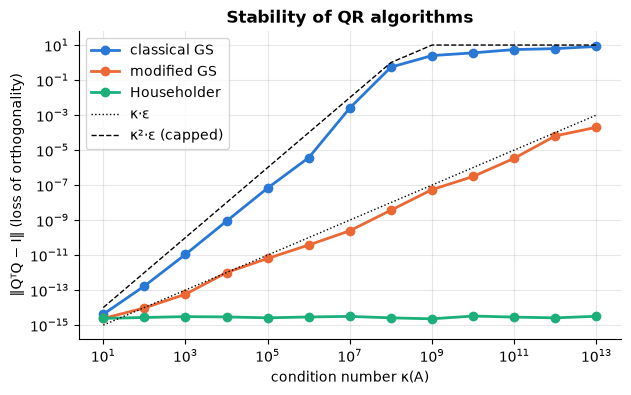

      classical GS modified GS Householder
1e+01      4.1e-15     2.4e-15     2.4e-15
1e+05      6.8e-08     6.4e-12     2.6e-15
1e+09      2.5e+00     5.5e-08     2.3e-15
1e+13      8.3e+00     2.0e-04     3.2e-15


In [5]:
def cgs(A):
    m, n = A.shape; Q = np.zeros((m, n)); R = np.zeros((n, n))
    for j in range(n):
        R[:j, j] = Q[:, :j].T @ A[:, j]                 # projections of the ORIGINAL column
        v = A[:, j] - Q[:, :j] @ R[:j, j]
        R[j, j] = np.linalg.norm(v); Q[:, j] = v / R[j, j]
    return Q, R

def mgs(A):
    V = np.array(A, dtype=float); m, n = V.shape; Q = np.zeros((m, n)); R = np.zeros((n, n))
    for j in range(n):
        R[j, j] = np.linalg.norm(V[:, j]); Q[:, j] = V[:, j] / R[j, j]
        R[j, j + 1:] = Q[:, j] @ V[:, j + 1:]           # remove q_j from all LATER columns right away
        V[:, j + 1:] -= np.outer(Q[:, j], R[j, j + 1:])
    return Q, R

def householder_qr(A):
    R = np.array(A, dtype=float); m, n = R.shape; Q = np.eye(m)
    for k in range(n):
        x = R[k:, k]
        v = x.copy(); v[0] += np.copysign(np.linalg.norm(x), x[0])   # sign choice avoids cancellation
        if np.linalg.norm(v) == 0:
            continue
        v /= np.linalg.norm(v)
        R[k:, k:] -= 2 * np.outer(v, v @ R[k:, k:])                  # apply H = I - 2vv^T on the left
        Q[:, k:] -= 2 * np.outer(Q[:, k:] @ v, v)                     # accumulate Q = H1 H2 ... Hn
    return Q[:, :n], np.triu(R[:n])

def matrix_with_condition(m, n, kappa, seed=0):
    r = np.random.default_rng(seed)
    U, _ = np.linalg.qr(r.normal(size=(m, n))); V, _ = np.linalg.qr(r.normal(size=(n, n)))
    return U @ np.diag(np.logspace(0, -np.log10(kappa), n)) @ V.T   # singular values from 1 down to 1/kappa

kappas = np.logspace(1, 13, 13)
loss = {"classical GS": [], "modified GS": [], "Householder": []}
for kap in kappas:
    A_k = matrix_with_condition(80, 20, kap)
    for name, fn in [("classical GS", cgs), ("modified GS", mgs), ("Householder", householder_qr)]:
        Q, R = fn(A_k)
        assert np.allclose(Q @ R, A_k, atol=1e-10)                    # all three reproduce A
        loss[name].append(np.linalg.norm(Q.T @ Q - np.eye(20)))
fig, ax = plt.subplots(figsize=(7, 4))
for name, vals in loss.items():
    ax.loglog(kappas, np.maximum(vals, 1e-17), "o-", label=name)
ax.loglog(kappas, 1e-16 * kappas, "k:", lw=1, label="κ·ε")
ax.loglog(kappas, np.minimum(1e-16 * kappas**2, 10), "k--", lw=1, label="κ²·ε (capped)")
ax.set_xlabel("condition number κ(A)"); ax.set_ylabel("‖QᵀQ − I‖ (loss of orthogonality)")
ax.set_title("Stability of QR algorithms"); ax.legend(); plt.show()
print(pd.DataFrame(loss, index=[f"{k:.0e}" for k in kappas]).iloc[[0, 4, 8, 12]].map(lambda v: f"{v:.1e}"))

**What just happened?** All three algorithms reproduce $A = QR$, but their $Q$'s are very different. Householder stays orthogonal to about $10^{-15}$ for every condition number. Modified Gram–Schmidt degrades along the $\kappa\varepsilon$ line, and classical Gram–Schmidt along $\kappa^2\varepsilon$ until its $Q$ is not orthogonal at all (loss of order 1). Same mathematics, different arithmetic order, very different numerics.

**Normal equations square the condition number.** The textbook formula $x = (A^\top A)^{-1}A^\top b$ solves the **normal equations** $A^\top A x = A^\top b$. But $\kappa(A^\top A) = \kappa(A)^2$ (the singular values get squared), so you lose *twice* as many digits as necessary. Let us compare on problems where we know the exact answer.

In [6]:
rows = []
for kap in [1e2, 1e4, 1e6, 1e8]:
    A_k = matrix_with_condition(200, 20, kap, seed=1)
    x_true = rng.normal(size=20); b_k = A_k @ x_true                  # consistent system: exact answer known
    x_ne = np.linalg.solve(A_k.T @ A_k, A_k.T @ b_k)                   # normal equations
    Q, R = householder_qr(A_k); x_qr = sla.solve_triangular(R, Q.T @ b_k)
    x_ls = np.linalg.lstsq(A_k, b_k, rcond=None)[0]                    # SVD-based LAPACK routine
    err = lambda x: np.linalg.norm(x - x_true) / np.linalg.norm(x_true)
    rows.append({"κ(A)": f"{kap:.0e}", "κ(AᵀA) measured": f"{np.linalg.cond(A_k.T @ A_k):.1e}",
                 "error: normal equations": f"{err(x_ne):.1e}", "error: Householder QR": f"{err(x_qr):.1e}",
                 "error: np.linalg.lstsq": f"{err(x_ls):.1e}"})
pd.DataFrame(rows)

,κ(A),κ(AᵀA) measured,error: normal equations,error: Householder QR,error: np.linalg.lstsq
0,1e+02,1.0e+04,3.8e-13,1.5e-15,1.8e-15
1,1e+04,1.0e+08,1.4e-09,4.6e-13,9.6e-14
2,1e+06,1.0e+12,1.0e-05,2.6e-12,2.5e-12
3,1e+08,1.0e+16,5.8e-03,1.1e-09,2.5e-10


**What just happened?** The measured $\kappa(A^\top A)$ is the square of $\kappa(A)$ (until it saturates near $10^{16}$, where $A^\top A$ is numerically singular). The normal-equation error grows like $\kappa^2\varepsilon$ and is useless by $\kappa = 10^8$, while QR and `lstsq` lose only about $\kappa\varepsilon$.

> 🎓 **Exam / interview tip.** "How would you solve linear regression numerically?" Good answer: QR (or SVD for rank-deficient problems, or Cholesky on $X^\top X + \lambda I$ when the problem is well-conditioned and very tall, because it is cheapest). Explain the $\kappa^2$ issue of the normal equations.

**Complexity.** Householder QR: $2mn^2 - \tfrac23 n^3$ flops. Normal equations + Cholesky: $mn^2 + \tfrac13 n^3$ (about half, for $m \gg n$). SVD: several times more than QR.

---
## 4. Conditioning and backward error

> **In plain English:** some problems are so sensitive that tiny input changes swing the answer wildly; a good algorithm cannot fix that, but it should not make it worse.

**Condition number.** $\kappa(A) = \|A\|\,\|A^{-1}\|$, which equals $\sigma_{\max}/\sigma_{\min}$ in the 2-norm. It bounds how much relative input errors are magnified:

$$\frac{\|\hat x - x\|}{\|x\|} \;\lesssim\; \kappa(A) \cdot \frac{\|\delta A\|}{\|A\|}.$$

**Backward error.** Instead of asking "how wrong is $\hat x$?" (the *forward* error), ask "for what nearby matrix is $\hat x$ the *exact* answer?". For linear systems the normwise backward error is $\eta = \dfrac{\|b - A\hat x\|}{\|A\|\,\|\hat x\|}$. An algorithm is **backward stable** if $\eta = O(\varepsilon_{\text{mach}})$ always.

Putting them together gives the most useful rule of thumb in numerical computing:

$$\text{forward error} \;\lesssim\; \kappa(A) \times \text{backward error} \quad\Longrightarrow\quad \text{you lose about } \log_{10}\kappa(A) \text{ digits.}$$

The **Hilbert matrix** $H_{ij} = 1/(i + j - 1)$ is the classic ill-conditioned example.

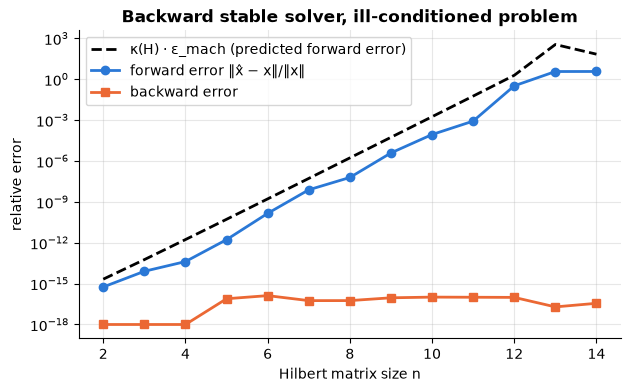

,n,κ(H),forward error,backward error
0,2,1.9e+01,5.7e-16,0.0e+00
4,6,1.5e+07,1.4e-10,1.3e-16
8,10,1.6e+13,8.7e-05,1.0e-16
11,13,3.2e+18,3.6e+00,2.0e-17


In [7]:
rows = []
for n in range(2, 15):
    H = sla.hilbert(n); x_true = np.ones(n); b_h = H @ x_true
    x_hat = np.linalg.solve(H, b_h)
    rows.append({"n": n, "κ(H)": np.linalg.cond(H),
                 "forward error": np.linalg.norm(x_hat - x_true) / np.linalg.norm(x_true),
                 "backward error": np.linalg.norm(b_h - H @ x_hat) / (np.linalg.norm(H, 2) * np.linalg.norm(x_hat))})
df_h = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(df_h["n"], df_h["κ(H)"] * 1.1e-16, "k--", label="κ(H) · ε_mach (predicted forward error)")
ax.semilogy(df_h["n"], df_h["forward error"], "o-", label="forward error ‖x̂ − x‖/‖x‖")
ax.semilogy(df_h["n"], np.maximum(df_h["backward error"], 1e-18), "s-", label="backward error")
ax.set_xlabel("Hilbert matrix size n"); ax.set_ylabel("relative error"); ax.legend()
ax.set_title("Backward stable solver, ill-conditioned problem"); plt.show()
df_h.iloc[[0, 4, 8, 11]].style.format({"κ(H)": "{:.1e}", "forward error": "{:.1e}", "backward error": "{:.1e}"})

**What just happened?** The backward error stays at the $10^{-16}$ level or below for every $n$: LU with pivoting did its job perfectly. Yet the forward error tracks $\kappa(H)\,\varepsilon_{\text{mach}}$ and reaches order 1 near $n = 12$ to $13$, where $\kappa(H) \approx 10^{16}$: the answer has *no* correct digits. That is not the algorithm's fault: the problem itself is that sensitive. In ML this appears as nearly collinear features (polynomial features, one-hot encodings with a redundant column), which is one reason regularisation helps.

> ⚠️ **Common mistake.** Checking a solution only by its residual $\|b - A\hat x\|$. A tiny residual proves a small *backward* error, not an accurate $x$; multiply by $\kappa(A)$ to bound the forward error.

---
## 5. Iterative solvers: Jacobi, Gauss–Seidel, conjugate gradient

> **In plain English:** for huge systems, start from a guess and repeatedly improve it, using only cheap "matrix times vector" steps; the better behaved the matrix, the fewer steps you need.

Direct methods cost $O(n^3)$ time and $O(n^2)$ memory, which is impossible for $n = 10^6$. **Iterative methods** only need to compute $v \mapsto Av$, which costs $O(\text{nnz})$ for a sparse matrix (nnz = number of non-zeros).

**Stationary methods.** Split $A = D + L + U$ (diagonal, strictly lower, strictly upper):
- **Jacobi:** $x^{(k+1)} = D^{-1}\big(b - (L + U)x^{(k)}\big)$: update every unknown from the *old* values.
- **Gauss–Seidel:** $x^{(k+1)} = (D + L)^{-1}\big(b - Ux^{(k)}\big)$: use each new value as soon as it is computed.
Both converge for strictly diagonally dominant or (Gauss–Seidel) SPD matrices, at a linear rate set by the spectral radius of the iteration matrix, which can be painfully close to 1.

**Conjugate gradient (CG)** (Hestenes and Stiefel, 1952) for SPD $A$ minimises $\tfrac12 x^\top A x - b^\top x$ along mutually **$A$-conjugate** directions ($p_i^\top A p_j = 0$). Key facts:
- in exact arithmetic it finds the exact solution in at most $n$ steps;
- the error after $k$ steps satisfies $\|e_k\|_A \le 2\left(\dfrac{\sqrt\kappa - 1}{\sqrt\kappa + 1}\right)^k \|e_0\|_A$, so the number of iterations grows like $\sqrt{\kappa}$, not $\kappa$;
- each step costs one matrix-vector product plus a few vector operations, $O(\text{nnz} + n)$.

Test matrix: the 1-D Poisson (second-difference) matrix $T = \operatorname{tridiag}(-1, 2, -1)$, the discrete version of $-u''$, which is SPD with $\kappa \approx 4(n+1)^2/\pi^2$.

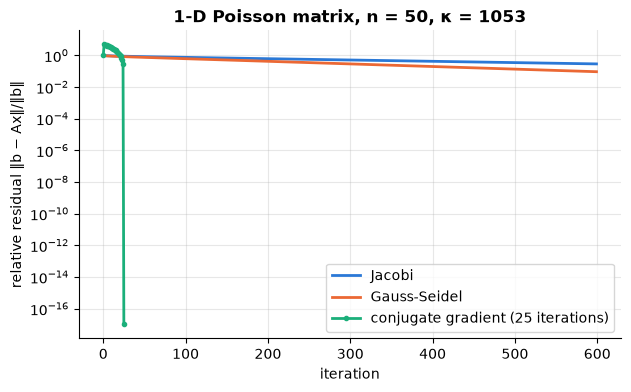

after 600 iterations: Jacobi 2.9e-01, Gauss-Seidel 9.4e-02; CG reached 0.0e+00 in 25


In [8]:
def jacobi(A, b, iters):
    D = np.diag(A); R = A - np.diag(D); x = np.zeros_like(b); res = []
    for _ in range(iters):
        x = (b - R @ x) / D                                   # all unknowns from the old x
        res.append(np.linalg.norm(b - A @ x) / np.linalg.norm(b))
    return x, res

def gauss_seidel(A, b, iters):
    n = len(b); x = np.zeros_like(b); res = []
    for _ in range(iters):
        for i in range(n):                                    # each new x[i] is used immediately
            x[i] = (b[i] - A[i, :i] @ x[:i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
        res.append(np.linalg.norm(b - A @ x) / np.linalg.norm(b))
    return x, res

def conjugate_gradient(matvec, b, tol=1e-10, max_iter=10_000, precond=None):
    """CG for SPD systems. matvec(v) returns A v. precond(r) applies M^-1 (optional)."""
    x = np.zeros_like(b); r = b.copy()
    z = precond(r) if precond else r
    p = z.copy(); rz = r @ z; res = [1.0]; nb_ = np.linalg.norm(b)
    for _ in range(max_iter):
        Ap = matvec(p)
        alpha = rz / (p @ Ap)                                 # exact line search along p
        x += alpha * p; r -= alpha * Ap
        res.append(np.linalg.norm(r) / nb_)
        if res[-1] < tol:
            break
        z = precond(r) if precond else r
        rz_new = r @ z
        p = z + (rz_new / rz) * p                             # next direction, A-conjugate to the previous ones
        rz = rz_new
    return x, res

n = 50
T = 2 * np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1)
b_t = np.ones(n); x_exact = np.linalg.solve(T, b_t)
_, r_j = jacobi(T, b_t, 600); _, r_gs = gauss_seidel(T, b_t, 600)
x_cg, r_cg = conjugate_gradient(lambda v: T @ v, b_t)
assert np.allclose(x_cg, x_exact)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(r_j, label="Jacobi"); ax.semilogy(r_gs, label="Gauss-Seidel")
ax.semilogy(np.maximum(r_cg, 1e-17), "o-", ms=3, label=f"conjugate gradient ({len(r_cg) - 1} iterations)")
ax.set_xlabel("iteration"); ax.set_ylabel("relative residual ‖b − Ax‖/‖b‖")
ax.set_title(f"1-D Poisson matrix, n = {n}, κ = {np.linalg.cond(T):.0f}"); ax.legend(); plt.show()
print(f"after 600 iterations: Jacobi {r_j[-1]:.1e}, Gauss-Seidel {r_gs[-1]:.1e}; CG reached {r_cg[-1]:.1e} in {len(r_cg) - 1}")

In [9]:
# CG iterations versus condition number (n = 300, eigenvalues spread evenly between 1 and kappa)
Qr, _ = np.linalg.qr(rng.normal(size=(300, 300)))
rows = []
for kap in [10, 100, 1_000, 10_000, 100_000]:
    A_s = Qr @ np.diag(np.linspace(1, kap, 300)) @ Qr.T
    _, res = conjugate_gradient(lambda v: A_s @ v, np.ones(300), tol=1e-8)
    bound = math.ceil(math.log(2 / 1e-8) / -math.log((math.sqrt(kap) - 1) / (math.sqrt(kap) + 1)))
    rows.append({"κ": kap, "√κ": round(math.sqrt(kap), 1), "CG iterations to 1e-8": len(res) - 1,
                 "√κ-based bound": bound, "n (exact-arithmetic limit)": 300})
df_cg = pd.DataFrame(rows)

# Preconditioning: a badly scaled SPD matrix; Jacobi (diagonal) preconditioner M = diag(A)
d_scale = np.logspace(0, 3, 300)
A_bs = d_scale[:, None] * (Qr @ np.diag(np.linspace(1, 10, 300)) @ Qr.T) * d_scale[None, :]
b_bs = rng.normal(size=300)
_, res_plain = conjugate_gradient(lambda v: A_bs @ v, b_bs, tol=1e-8)
diagA = np.diag(A_bs).copy()
x_pcg, res_pcg = conjugate_gradient(lambda v: A_bs @ v, b_bs, tol=1e-8, precond=lambda r: r / diagA)
count = {"plain": 0, "pre": 0}
def cb_plain(xk): count["plain"] += 1
def cb_pre(xk): count["pre"] += 1
x_sc, info = spla.cg(A_bs, b_bs, rtol=1e-8, maxiter=20_000, callback=cb_plain)
spla.cg(A_bs, b_bs, rtol=1e-8, maxiter=20_000, M=sp.diags(1 / diagA), callback=cb_pre)
assert np.allclose(x_pcg, np.linalg.solve(A_bs, b_bs), rtol=1e-5)
print(f"badly scaled matrix: κ(A) = {np.linalg.cond(A_bs):.1e}, κ after diagonal scaling = "
      f"{np.linalg.cond(A_bs / np.sqrt(np.outer(diagA, diagA))):.1e}")
print(f"CG iterations: plain {len(res_plain) - 1}, Jacobi-preconditioned {len(res_pcg) - 1}"
      f" | scipy.sparse.linalg.cg: plain {count['plain']}, preconditioned {count['pre']}")
df_cg

badly scaled matrix: κ(A) = 1.7e+06, κ after diagonal scaling = 1.0e+01
CG iterations: plain 5186, Jacobi-preconditioned 35 | scipy.sparse.linalg.cg: plain 5186, preconditioned 35


,κ,√κ,CG iterations to 1e-8,√κ-based bound,n (exact-arithmetic limit)
0,10,3.2,29,30,300
1,100,10.0,78,96,300
2,1000,31.6,106,303,300
3,10000,100.0,115,956,300
4,100000,316.2,121,3023,300


**What just happened?**
- On the Poisson matrix, Jacobi and Gauss–Seidel crawl: after 600 iterations their residuals are still about 0.3 and 0.09 (Gauss–Seidel converges about twice as fast as Jacobi, as theory predicts for this matrix). CG solves the 50-unknown system exactly in just 25 iterations: the guarantee is "at most $n = 50$", and here only half are needed because the symmetric right-hand side `ones` excites only the 25 symmetric eigenvectors. Notice that CG's *residual* first goes **up**: CG minimises the error in the $A$-norm at every step, not the residual, so the residual need not decrease monotonically.
- In the table, the $\sqrt\kappa$ bound is tight for small $\kappa$ (29 iterations against a bound of 30 at $\kappa = 10$), but for large $\kappa$ CG needs far fewer iterations than the bound, levelling off around 100 to 120. The bound is a worst case; CG adapts to the actual eigenvalue distribution, and with only 300 eigenvalues it can never need more than 300 steps in exact arithmetic.
- Diagonal (**Jacobi**) **preconditioning** rescales the badly scaled matrix from $\kappa \approx 10^6$ to $\kappa \approx 10$, and the iteration count drops from thousands to a few dozen. SciPy's `cg` (with `rtol`, the current keyword) reports iteration counts close to ours. Better preconditioners (incomplete Cholesky, multigrid) are what make industrial-scale solvers work.

**Complexity.** Per iteration, $O(\text{nnz})$ for all three methods. Total for CG: $O(\sqrt{\kappa}\,\text{nnz})$ to reach a fixed tolerance. Memory: a handful of vectors, $O(n)$.

---
## 6. Eigenvalue algorithms and PageRank

> **In plain English:** multiplying a vector by a matrix over and over makes it line up with the matrix's strongest direction; small twists of this idea find any eigenvalue you want.

**Power iteration.** $v_{k+1} = Av_k / \|Av_k\|$. If $|\lambda_1| > |\lambda_2| \ge \dots$, then $v_k$ converges to the top eigenvector at the linear rate $|\lambda_2/\lambda_1|$, and the **Rayleigh quotient** $r(v) = \dfrac{v^\top A v}{v^\top v}$ estimates $\lambda_1$ (for symmetric $A$ its error is the *square* of the vector error).

**Inverse iteration with shift $\sigma$:** power iteration on $(A - \sigma I)^{-1}$ finds the eigenvalue **closest to $\sigma$**, at rate $|\lambda_{\text{closest}} - \sigma| / |\lambda_{\text{next}} - \sigma|$. Each step is a linear solve (factor $A - \sigma I$ once).

**Rayleigh quotient iteration (RQI):** update the shift every step to the current Rayleigh quotient. For symmetric matrices it converges **cubically**: the number of correct digits roughly triples each step.

**QR algorithm** (Francis and Kublanovskaya, 1961): repeat $A_k = Q_kR_k$, $A_{k+1} = R_kQ_k$. Each $A_{k+1} = Q_k^\top A_k Q_k$ is similar to $A$ (same eigenvalues), and for distinct $|\lambda_i|$ the iterates converge to a triangular (diagonal, if symmetric) matrix with the eigenvalues on the diagonal. Real implementations (LAPACK, behind `np.linalg.eig`) first reduce to Hessenberg/tridiagonal form and use shifts, making it $O(n^3)$ overall.

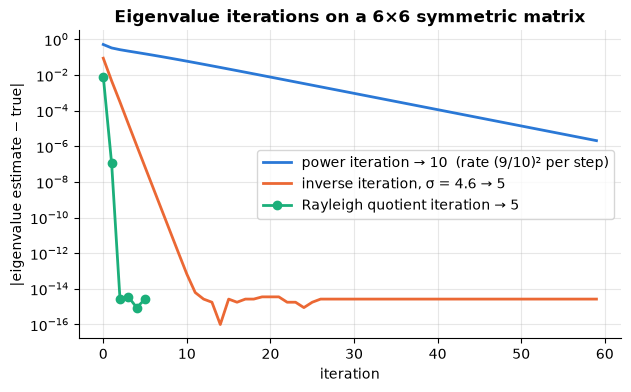

RQI errors: ['8.2e-03', '1.1e-07', '2.7e-15', '3.6e-15', '8.9e-16', '2.7e-15']


In [10]:
Qe, _ = np.linalg.qr(rng.normal(size=(6, 6)))
true_eigs = np.array([10.0, 9.0, 5.0, 3.0, 2.0, 1.0])
A_e = Qe @ np.diag(true_eigs) @ Qe.T                          # symmetric, eigenvalues known

def power_iteration(A, iters, v0):
    v = v0 / np.linalg.norm(v0); hist = []
    for _ in range(iters):
        v = A @ v; v /= np.linalg.norm(v)
        hist.append(v @ A @ v)                                # Rayleigh quotient estimate
    return v, hist

def inverse_iteration(A, sigma, iters, v0):
    lu = sla.lu_factor(A - sigma * np.eye(len(A)))            # factor once, reuse every step
    v = v0 / np.linalg.norm(v0); hist = []
    for _ in range(iters):
        v = sla.lu_solve(lu, v); v /= np.linalg.norm(v)
        hist.append(v @ A @ v)
    return v, hist

def rayleigh_quotient_iteration(A, v0, iters):
    v = v0 / np.linalg.norm(v0); mu = v @ A @ v; hist = [mu]
    for _ in range(iters):
        try:
            w = np.linalg.solve(A - mu * np.eye(len(A)), v)
        except np.linalg.LinAlgError:
            break                                             # shift hit an eigenvalue exactly
        v = w / np.linalg.norm(w); mu = v @ A @ v; hist.append(mu)
    return v, hist

v0 = rng.normal(size=6)
_, h_pow = power_iteration(A_e, 60, v0)
_, h_inv = inverse_iteration(A_e, 4.6, 60, v0)
v_start = Qe[:, 2] + 0.1 * rng.normal(size=6)                 # rough guess near the eigenvector of 5
_, h_rqi = rayleigh_quotient_iteration(A_e, v_start, 5)

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(np.maximum(np.abs(np.array(h_pow) - 10), 1e-16), label="power iteration → 10  (rate (9/10)² per step)")
ax.semilogy(np.maximum(np.abs(np.array(h_inv) - 5), 1e-16), label="inverse iteration, σ = 4.6 → 5")
ax.semilogy(np.maximum(np.abs(np.array(h_rqi) - 5), 1e-16), "o-", label="Rayleigh quotient iteration → 5")
ax.set_xlabel("iteration"); ax.set_ylabel("|eigenvalue estimate − true|"); ax.legend()
ax.set_title("Eigenvalue iterations on a 6×6 symmetric matrix"); plt.show()
print("RQI errors:", [f"{abs(m - 5):.1e}" for m in h_rqi])

**What just happened?**
- **Power iteration** converges slowly because $|\lambda_2/\lambda_1| = 0.9$; the Rayleigh-quotient *eigenvalue* error shrinks like $0.9^{2k} = 0.81^k$ (squared, because $A$ is symmetric).
- **Inverse iteration** with shift 4.6 targets the eigenvalue 5 (the closest one); its rate is $|5 - 4.6| / |3 - 4.6| = 0.25$ per step for the vector, so it converges much faster.
- **RQI** gets from a rough guess to machine precision in about 3 steps; look at the printed errors, where the exponent roughly triples each time.

**PageRank by power iteration.** Model a random surfer on a directed graph of $n$ pages: with probability $\alpha = 0.85$ follow a random outgoing link, otherwise (or from a page with no out-links, a "dangling" node) jump to a uniformly random page. The PageRank vector $\pi$ is the stationary distribution, $\pi = G\pi$ for the column-stochastic **Google matrix** $G = \alpha (S) + (1 - \alpha)\tfrac1n \mathbf{1}\mathbf{1}^\top$. Its largest eigenvalue is 1 and the second is at most $\alpha$ in magnitude, so power iteration converges at rate $\le 0.85$ regardless of the web's size, and each step is one sparse matrix-vector product.

60 pages, 193 links, 2 dangling pages; converged in 47 iterations; matches nx.pagerank (max diff 2.1e-12)
top pages: [19, 38, 59, 34, 10] scores: [0.0474 0.043  0.0412 0.0359 0.0335]


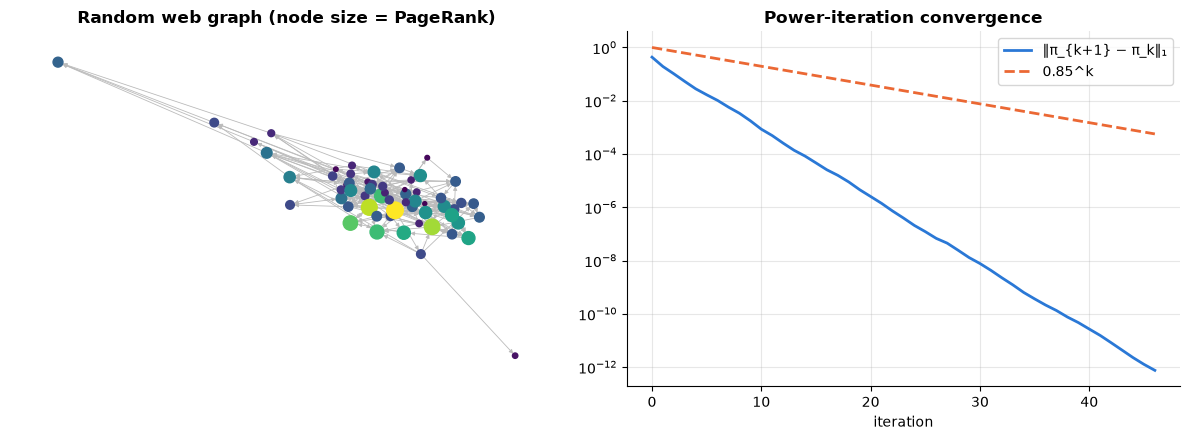

In [11]:
G_web = nx.gnp_random_graph(60, 0.06, directed=True, seed=3)
n_web = G_web.number_of_nodes()
A_web = nx.to_numpy_array(G_web, nodelist=range(n_web)).T          # A[j, i] = 1 if edge i -> j
out_deg = A_web.sum(axis=0)
dangling = out_deg == 0
S = np.where(dangling, 1.0 / n_web, A_web / np.where(dangling, 1, out_deg))   # column-stochastic

def pagerank_power(S, alpha=0.85, tol=1e-12, max_iter=500):
    n = S.shape[0]; pi = np.full(n, 1 / n); diffs = []
    for _ in range(max_iter):
        new = alpha * (S @ pi) + (1 - alpha) / n                    # one step of the random surfer
        diffs.append(np.abs(new - pi).sum()); pi = new
        if diffs[-1] < tol:
            break
    return pi, diffs

pi, diffs = pagerank_power(S)
pr_nx = nx.pagerank(G_web, alpha=0.85, tol=1e-12)
pr_nx = np.array([pr_nx[i] for i in range(n_web)])
assert np.allclose(pi, pr_nx, atol=1e-9)
print(f"{len(G_web)} pages, {G_web.number_of_edges()} links, {dangling.sum()} dangling pages;"
      f" converged in {len(diffs)} iterations; matches nx.pagerank (max diff {np.abs(pi - pr_nx).max():.1e})")
top = np.argsort(-pi)[:5]
print("top pages:", [int(t) for t in top], "scores:", np.round(pi[top], 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
pos = nx.spring_layout(G_web, seed=1)
nx.draw_networkx(G_web, pos, ax=axes[0], node_size=3000 * pi, node_color=pi, cmap="viridis",
                 with_labels=False, arrowsize=6, edge_color="#bbbbbb", width=0.6)
axes[0].set_title("Random web graph (node size = PageRank)"); axes[0].axis("off")
axes[1].semilogy(diffs, label="‖π_{k+1} − π_k‖₁"); axes[1].semilogy(0.85 ** np.arange(len(diffs)), "--", label="0.85^k")
axes[1].set_xlabel("iteration"); axes[1].set_title("Power-iteration convergence"); axes[1].legend()
plt.tight_layout(); plt.show()

In [12]:
# The (unshifted) QR algorithm on a small symmetric matrix
Ak = A_e.copy(); off = []
for k in range(80):
    Qk, Rk = np.linalg.qr(Ak)
    Ak = Rk @ Qk                                            # similar to A: same eigenvalues
    off.append(np.linalg.norm(Ak - np.diag(np.diag(Ak))))
print("diagonal after 80 QR steps:", np.round(np.diag(Ak), 8))
print("true eigenvalues          :", true_eigs)
print("off-diagonal norm at steps 1, 20, 40, 80:", [f"{off[i]:.1e}" for i in [0, 19, 39, 79]])
assert np.allclose(np.sort(np.diag(Ak)), np.sort(np.linalg.eigvalsh(A_e)), atol=1e-6)

diagonal after 80 QR steps: [9.99999976 9.00000024 5.         3.         2.         1.        ]
true eigenvalues          : [10.  9.  5.  3.  2.  1.]
off-diagonal norm at steps 1, 20, 40, 80: ['5.8e+00', '3.6e-01', '4.7e-02', '6.9e-04']


**What just happened?** Our PageRank equals NetworkX's to about $10^{-12}$, and the step-to-step change shrinks at least as fast as $0.85^k$. Pages with many incoming links from important pages get the biggest scores. The plain QR algorithm drives the off-diagonal part towards zero and leaves the eigenvalues, sorted by size, on the diagonal; convergence is slow for the pair 10 and 9 (ratio 0.9), which is exactly why practical versions use **shifts**.

**Complexity.** Power iteration: one matrix-vector product per step, $O(\text{nnz})$; iterations $\approx \log(\text{tol}) / \log|\lambda_2/\lambda_1|$. Inverse iteration: one $O(n^3)$ factorisation then $O(n^2)$ per step. Full symmetric eigendecomposition (`eigh`): $O(n^3)$.

> 🎓 **Exam / interview tip.** "Why does power iteration fail when $|\lambda_1| = |\lambda_2|$?" (for example eigenvalues $+1$ and $-1$: the vector keeps flipping between two directions). "Why does PageRank need the teleportation term?" (it makes the chain irreducible and aperiodic, so a unique stationary distribution exists and $|\lambda_2| \le \alpha$).

---
## 7. Sparse matrices

> **In plain English:** when almost every entry is zero, store only the non-zero ones and where they are; this turns impossible memory requirements into tiny ones.

**CSR (compressed sparse row)** stores three arrays:
- `data`: the non-zero values, row by row;
- `indices`: the column index of each value;
- `indptr`: length $n_{\text{rows}} + 1$; row $i$'s entries are `data[indptr[i]:indptr[i+1]]`.

**Worked example by hand:**

$$\begin{pmatrix} 5 & 0 & 0 & 1 \\ 0 & 0 & 2 & 0 \\ 0 & 3 & 0 & 4 \end{pmatrix}:\quad
\texttt{data} = [5, 1, 2, 3, 4],\ \texttt{indices} = [0, 3, 2, 1, 3],\ \texttt{indptr} = [0, 2, 3, 5].$$

CSR is fast for row slicing and matrix-vector products; **CSC** (compressed sparse column) is the same idea by columns, good for column slicing and used by sparse direct solvers; **COO** (coordinate triplets) is convenient for building a matrix. Memory is $O(\text{nnz})$ instead of $O(n^2)$, and $Ax$ costs $O(\text{nnz})$.

In [13]:
def dense_to_csr(M):
    data, indices, indptr = [], [], [0]
    for row in M:
        for j, v in enumerate(row):
            if v != 0:
                data.append(v); indices.append(j)
        indptr.append(len(data))                       # where the next row starts
    return np.array(data, float), np.array(indices), np.array(indptr)

def csr_matvec(data, indices, indptr, x):
    y = np.zeros(len(indptr) - 1)
    for i in range(len(y)):
        start, end = indptr[i], indptr[i + 1]
        y[i] = data[start:end] @ x[indices[start:end]]  # only the non-zeros of row i
    return y

M_small = np.array([[5., 0, 0, 1], [0, 0, 2, 0], [0, 3, 0, 4]])
d_, i_, p_ = dense_to_csr(M_small)
print("data =", d_, "| indices =", i_, "| indptr =", p_)
S_ref = sp.csr_matrix(M_small)
assert np.array_equal(d_, S_ref.data) and np.array_equal(i_, S_ref.indices) and np.array_equal(p_, S_ref.indptr)
x4 = rng.normal(size=4)
assert np.allclose(csr_matvec(d_, i_, p_, x4), M_small @ x4)
print("our CSR arrays are identical to scipy.sparse.csr_matrix, and the matvec agrees")

def laplacian_2d(N):
    """5-point Laplacian on an N x N grid (N^2 unknowns), built with Kronecker products."""
    T1 = sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(N, N))
    I = sp.identity(N)
    return (sp.kron(I, T1) + sp.kron(T1, I)).tocsr()

rows = []
for N in [10, 50, 100, 300]:
    L2 = laplacian_2d(N); n2 = N * N
    csr_bytes = L2.data.nbytes + L2.indices.nbytes + L2.indptr.nbytes
    rows.append({"grid": f"{N}×{N}", "unknowns": n2, "non-zeros": L2.nnz,
                 "dense memory": f"{n2 * n2 * 8 / 1e6:,.1f} MB", "CSR memory": f"{csr_bytes / 1e6:.3f} MB"})
pd.DataFrame(rows)

data = [5. 1. 2. 3. 4.] | indices = [0 3 2 1 3] | indptr = [0 2 3 5]
our CSR arrays are identical to scipy.sparse.csr_matrix, and the matvec agrees


,grid,unknowns,non-zeros,dense memory,CSR memory
0,10×10,100,460,0.1 MB,0.006 MB
1,50×50,2500,12300,50.0 MB,0.158 MB
2,100×100,10000,49600,800.0 MB,0.635 MB
3,300×300,90000,448800,"64,800.0 MB",5.746 MB


3600 unknowns, 17760 non-zeros: spsolve 0.091 s | scipy cg 124 iterations 0.050 s | our CG 124 iterations


4 smallest eigenvalues (eigsh): [0.005304 0.013252 0.013252 0.0212  ] | exact: [0.005304 0.013252 0.013252 0.0212  ]


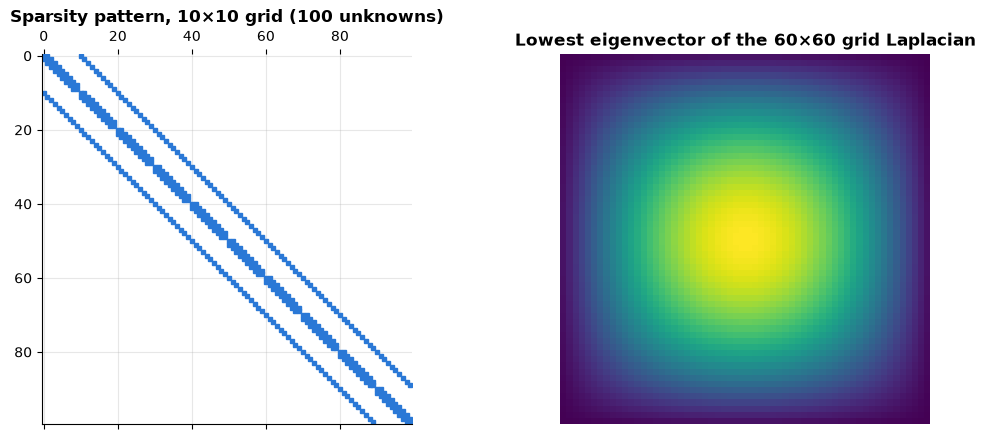

In [14]:
N = 60; L2 = laplacian_2d(N); n2 = N * N
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].spy(laplacian_2d(10), markersize=2.5); axes[0].set_title("Sparsity pattern, 10×10 grid (100 unknowns)")

b2 = np.ones(n2)
t0 = time.perf_counter(); x_direct = spla.spsolve(L2.tocsc(), b2); t_direct = time.perf_counter() - t0
its = []
t0 = time.perf_counter(); x_it, info = spla.cg(L2, b2, rtol=1e-10, callback=lambda xk: its.append(1)); t_cg = time.perf_counter() - t0
x_ours, res_ours = conjugate_gradient(lambda v: L2 @ v, b2, tol=1e-10)
assert info == 0 and np.allclose(x_it, x_direct, atol=1e-6) and np.allclose(x_ours, x_direct, atol=1e-6)
print(f"{n2} unknowns, {L2.nnz} non-zeros: spsolve {t_direct:.3f} s | scipy cg {len(its)} iterations {t_cg:.3f} s"
      f" | our CG {len(res_ours) - 1} iterations")

# Smallest eigenvalues with eigsh (shift-invert around 0) vs the exact formula
vals = np.sort(spla.eigsh(L2, k=4, sigma=0, which="LM", return_eigenvectors=False))
lam = lambda i, j: 4 * np.sin(i * np.pi / (2 * (N + 1)))**2 + 4 * np.sin(j * np.pi / (2 * (N + 1)))**2
exact4 = np.sort([lam(i, j) for i in range(1, 4) for j in range(1, 4)])[:4]
assert np.allclose(vals, exact4)
print("4 smallest eigenvalues (eigsh):", np.round(vals, 6), "| exact:", np.round(exact4, 6))

_, vecs = spla.eigsh(L2, k=1, sigma=0, which="LM")
axes[1].imshow(vecs[:, 0].reshape(N, N), cmap="viridis"); axes[1].set_title("Lowest eigenvector of the 60×60 grid Laplacian")
axes[1].axis("off"); plt.tight_layout(); plt.show()

**What just happened?** Our CSR arrays are byte-for-byte what SciPy builds. For a $300 \times 300$ grid (90,000 unknowns), the dense matrix would need about 65 GB while CSR needs a few megabytes. The sparse direct solver (`spsolve`, a sparse LU) and CG both solve the 3,600-unknown Poisson problem quickly, and `eigsh` with shift-invert finds the smallest eigenvalues, matching the exact formula $4\sin^2\frac{i\pi}{2(N+1)} + 4\sin^2\frac{j\pi}{2(N+1)}$; note the repeated eigenvalue, from the symmetry $i \leftrightarrow j$. The lowest eigenvector is a smooth bump: the fundamental vibration mode of a square drum.

> ⚠️ **Common mistake.** Calling `.toarray()` or `np.array(...)` on a large sparse matrix "just to check something", or doing `A[i, j] = v` in a loop on a CSR matrix (each insert is $O(\text{nnz})$). Build in COO or LIL format, then convert once with `.tocsr()`.

---
## 8. Randomized linear algebra

> **In plain English:** multiply a huge matrix by a few random vectors to get a small "sketch" that captures its important directions, then do the expensive maths on the small sketch.

**Randomized SVD** (Halko, Martinsson and Tropp, 2011). To approximate the top-$k$ singular triplets of an $m \times n$ matrix $A$:
1. Draw a Gaussian random matrix $\Omega$ of size $n \times (k + p)$ with a small **oversampling** $p$ (say 10).
2. Form $Y = (AA^\top)^q A\Omega$, with $q = 0, 1, 2$ **power iterations** to sharpen a slowly decaying spectrum.
3. Orthonormalise: $Y = QR$. Now $A \approx QQ^\top A$.
4. Compute the SVD of the small matrix $B = Q^\top A$ ($(k + p) \times n$): $B = \tilde U \Sigma V^\top$, and set $U = Q\tilde U$.

Cost: $O(mn(k + p))$ instead of $O(mn\min(m, n))$ for a full SVD. The **Eckart–Young theorem** says the best possible rank-$k$ error in the spectral norm is $\sigma_{k+1}$, which gives us a yardstick.

**Sketch-and-solve least squares.** For a very tall $A$ ($m \gg n$), multiply both $A$ and $b$ by a random $s \times m$ sketching matrix $S$ ($n < s \ll m$) and solve the small problem $\min\|S(Ax - b)\|$. With high probability its residual is within a factor $1 + \epsilon$ of the optimum. **CountSketch** (each row of $A$ is added, with a random sign, to one random row of the sketch) costs only $O(\text{nnz}(A))$.

In [15]:
def randomized_svd(A, k, p=10, q=1, seed=0):
    r = np.random.default_rng(seed)
    Y = A @ r.normal(size=(A.shape[1], k + p))           # random projection of the column space
    for _ in range(q):                                   # power iterations (re-orthonormalise for stability)
        Y, _ = np.linalg.qr(Y); Y = A @ (A.T @ Y)
    Q, _ = np.linalg.qr(Y)
    Ub, s, Vt = np.linalg.svd(Q.T @ A, full_matrices=False)   # SVD of a small (k+p) x n matrix
    return (Q @ Ub)[:, :k], s[:k], Vt[:k]

m, n_cols, k = 2000, 800, 20
U0, _ = np.linalg.qr(rng.normal(size=(m, 100))); V0, _ = np.linalg.qr(rng.normal(size=(n_cols, 100)))
sing = 1.0 / (1 + np.arange(100)) ** 1.0                 # slowly decaying spectrum: a hard case
A_big = U0 @ np.diag(sing) @ V0.T + 1e-3 * rng.normal(size=(m, n_cols)) / math.sqrt(m)

t0 = time.perf_counter(); s_full = np.linalg.svd(A_big, compute_uv=False); t_full = time.perf_counter() - t0
rows = []
for q in [0, 1, 2]:
    t0 = time.perf_counter(); U_r, s_r, Vt_r = randomized_svd(A_big, k, q=q); t_r = time.perf_counter() - t0
    err = np.linalg.norm(A_big - (U_r * s_r) @ Vt_r, 2)
    rows.append({"power iterations q": q, "spectral error ‖A − A_k‖": err, "optimal σ_{k+1}": s_full[k],
                 "ratio to optimal": err / s_full[k], "max rel. error of top-20 σ": np.max(np.abs(s_r - s_full[:k]) / s_full[:k]),
                 "seconds": t_r})
print(f"full SVD of {m}x{n_cols}: {t_full:.2f} s (singular values only)")
pd.DataFrame(rows).style.format({"spectral error ‖A − A_k‖": "{:.4f}", "optimal σ_{k+1}": "{:.4f}",
                                 "ratio to optimal": "{:.3f}", "max rel. error of top-20 σ": "{:.1e}", "seconds": "{:.3f}"})

full SVD of 2000x800: 1.07 s (singular values only)


,power iterations q,spectral error ‖A − A_k‖,optimal σ_{k+1},ratio to optimal,max rel. error of top-20 σ,seconds
0,0,0.0858,0.0476,1.801,2.2e-01,0.087
1,1,0.0490,0.0476,1.029,5.3e-02,0.093
2,2,0.0477,0.0476,1.001,2.1e-02,0.149


In [16]:
# Sketch-and-solve least squares on a tall problem
m_t, n_t = 20_000, 40
A_t = rng.normal(size=(m_t, n_t)) * np.logspace(0, 1, n_t)
b_t2 = A_t @ rng.normal(size=n_t) + rng.normal(size=m_t)
x_opt = np.linalg.lstsq(A_t, b_t2, rcond=None)[0]
res_opt = np.linalg.norm(A_t @ x_opt - b_t2)

def count_sketch(A, b, s, seed=0):
    r = np.random.default_rng(seed)
    h = r.integers(0, s, size=A.shape[0])                # bucket for each row
    sign = r.choice([-1.0, 1.0], size=A.shape[0])        # random sign for each row
    SA = np.zeros((s, A.shape[1])); Sb = np.zeros(s)
    np.add.at(SA, h, sign[:, None] * A)                  # O(nnz(A)): each row touched once
    np.add.at(Sb, h, sign * b)
    return SA, Sb

rows = []
for s in [200, 800, 3200]:
    G = rng.normal(size=(s, m_t)) / math.sqrt(s)
    x_g = np.linalg.lstsq(G @ A_t, G @ b_t2, rcond=None)[0]
    SA, Sb = count_sketch(A_t, b_t2, s)
    x_c = np.linalg.lstsq(SA, Sb, rcond=None)[0]
    rows.append({"sketch size s": s, "Gaussian: residual / optimal": np.linalg.norm(A_t @ x_g - b_t2) / res_opt,
                 "CountSketch: residual / optimal": np.linalg.norm(A_t @ x_c - b_t2) / res_opt})
pd.DataFrame(rows).style.format({c: "{:.4f}" for c in rows[0] if c != "sketch size s"})

,sketch size s,Gaussian: residual / optimal,CountSketch: residual / optimal
0,200,1.1224,1.0813
1,800,1.0213,1.0420
2,3200,1.0065,1.0073


**What just happened?**
- Randomized SVD without power iterations ($q = 0$) is noticeably worse than optimal on this slowly decaying spectrum; with $q = 1$ or $2$ the error comes within a few percent of the Eckart–Young optimum $\sigma_{21}$, and the top singular values are accurate. It works on a $2000 \times 30$ sketch instead of the full matrix, which is where its speed advantage comes from on large matrices (on matrices this small, timings are dominated by overheads).
- Sketch-and-solve: with a sketch of a few hundred rows (out of 20,000), the least-squares residual is already within roughly 10 to 15% of the optimum, and the ratio approaches 1 as $s$ grows; CountSketch behaves like the Gaussian sketch at a fraction of the cost. In practice the sketch is used as a **preconditioner** (Blendenpik, LSRN) to get full accuracy.

**Complexity.** Randomized SVD: $O(mn(k + p)(2q + 1))$ flops, and the matrix is read only $2q + 2$ times, which is what matters when it does not fit in memory. CountSketch: $O(\text{nnz}(A))$.

---
## 9. Summary table

> **In plain English:** pick the tool by the shape and size of your matrix.

| Problem | Matrix | Method | Cost | Notes |
|---|---|---|---|---|
| $Ax = b$ | general, dense, $n \lesssim 10^4$ | LU with partial pivoting | $\tfrac23 n^3$, then $2n^2$ per RHS | `np.linalg.solve`, `lu_factor` |
| $Ax = b$ | SPD, dense | Cholesky | $\tfrac13 n^3$ | `cho_factor`; also tests SPD |
| $Ax = b$ | sparse, large | sparse LU (`spsolve`) or iterative | depends on fill-in | direct up to ~$10^6$ unknowns in 2-D |
| $Ax = b$ | SPD, sparse, huge | **CG** + preconditioner | $O(\sqrt\kappa\,\text{nnz})$ | `scipy.sparse.linalg.cg` |
| $Ax = b$ | non-symmetric, sparse | GMRES, BiCGSTAB | per iteration $O(\text{nnz})$ | `spla.gmres` |
| $\min\|Ax - b\|$ | dense, tall | Householder QR | $2mn^2$ | avoid normal equations if ill-conditioned |
| $\min\|Ax - b\|$ | rank-deficient | SVD (`lstsq`) | $O(mn^2)$ | gives the minimum-norm solution |
| $\min\|Ax - b\|$ | huge, tall | sketch-and-solve / sketch-preconditioned LSQR | $O(\text{nnz})$ + small solve | randomized |
| eigenvalues | dense symmetric | `eigh` (tridiagonal QR / divide-and-conquer) | $O(n^3)$ | all eigenpairs |
| a few eigenvalues | sparse | Lanczos (`eigsh`), shift-invert | per iteration $O(\text{nnz})$ | top or nearest-$\sigma$ |
| dominant eigenvector | stochastic / huge | power iteration | $O(\text{nnz})$ per step | PageRank |
| top-$k$ SVD | dense, large | randomized SVD | $O(mnk)$ | `sklearn.utils.extmath.randomized_svd` |

---
## 10. How this connects to modern AI

> **In plain English:** linear regression, Gaussian processes, recommender systems and LLM fine-tuning all spend their time inside the algorithms of this notebook.

**1. Ridge regression three ways.** Ridge solves $(X^\top X + \lambda I)w = X^\top y$: an SPD system. With $d$ features you can use **Cholesky** ($O(nd^2 + d^3)$) or **CG** using only products with $X$ and $X^\top$ (never forming the $d \times d$ matrix), which is how large sparse linear models (text features with millions of columns) are trained.

In [17]:
from sklearn.linear_model import Ridge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

n_s, d_s, lam_r = 3000, 300, 10.0
X_r = rng.normal(size=(n_s, d_s)); w_true = rng.normal(size=d_s)
y_r = X_r @ w_true + rng.normal(size=n_s)

t0 = time.perf_counter()
Lr = np.linalg.cholesky(X_r.T @ X_r + lam_r * np.eye(d_s))
w_chol = sla.cho_solve((Lr, True), X_r.T @ y_r); t_chol = time.perf_counter() - t0
t0 = time.perf_counter()
w_cg, res_r = conjugate_gradient(lambda v: X_r.T @ (X_r @ v) + lam_r * v, X_r.T @ y_r, tol=1e-12)
t_cg = time.perf_counter() - t0
w_sk = Ridge(alpha=lam_r, fit_intercept=False, solver="cholesky").fit(X_r, y_r).coef_
assert np.allclose(w_chol, w_sk) and np.allclose(w_cg, w_sk, atol=1e-8)
print(f"Cholesky {t_chol:.3f} s | CG {len(res_r) - 1} iterations, {t_cg:.3f} s (matrix-free) | both match sklearn Ridge")

# 2. Gaussian-process regression: everything goes through one Cholesky of K + noise*I
def gp_fit_predict(X, y, Xs, length=1.0, noise=0.1):
    K = rbf_kernel(X, X, length) + noise * np.eye(len(X))
    Lg = np.linalg.cholesky(K)                                 # O(n^3): the bottleneck
    alpha = sla.cho_solve((Lg, True), y)
    mean = rbf_kernel(Xs, X, length) @ alpha
    log_ml = -0.5 * y @ alpha - np.log(np.diag(Lg)).sum() - 0.5 * len(X) * np.log(2 * np.pi)
    return mean, log_ml                                        # log det K = 2 * sum(log diag L)

Xg = np.sort(rng.uniform(0, 10, size=(80, 1)), axis=0); yg = np.sin(Xg[:, 0]) + 0.3 * rng.normal(size=80)
Xs = np.linspace(0, 10, 200)[:, None]
mean, log_ml = gp_fit_predict(Xg, yg, Xs)
gpr = GaussianProcessRegressor(kernel=RBF(1.0, length_scale_bounds="fixed"), alpha=0.1, optimizer=None).fit(Xg, yg)
assert np.allclose(mean, gpr.predict(Xs)) and np.isclose(log_ml, gpr.log_marginal_likelihood_value_)
print(f"GP from scratch: log marginal likelihood {log_ml:.4f} = sklearn {gpr.log_marginal_likelihood_value_:.4f}")

sizes, times = [250, 500, 1000, 2000], []
for n_gp in sizes:
    Xn = rng.uniform(0, 10, size=(n_gp, 1)); K = rbf_kernel(Xn, Xn) + 0.1 * np.eye(n_gp)
    t0 = time.perf_counter(); np.linalg.cholesky(K); times.append(time.perf_counter() - t0)
print("Cholesky time for n =", sizes, "->", [f"{t * 1000:.1f} ms" for t in times],
      "(cubic growth; BLAS threading makes small sizes noisy)")

Cholesky 0.085 s | CG 24 iterations, 0.123 s (matrix-free) | both match sklearn Ridge
GP from scratch: log marginal likelihood -28.3171 = sklearn -28.3171


Cholesky time for n = [250, 500, 1000, 2000] -> ['38.1 ms', '30.8 ms', '246.2 ms', '735.8 ms'] (cubic growth; BLAS threading makes small sizes noisy)


**What just happened?** Cholesky, matrix-free CG and scikit-learn all give the same ridge coefficients. Our 15-line GP reproduces scikit-learn's predictions *and* its log marginal likelihood, using one Cholesky factorisation for both the solve and the log-determinant ($\log\det K = 2\sum_i \log L_{ii}$). That $O(n^3)$ factorisation is why exact GPs stop at roughly $10^4$ points, and why sparse/inducing-point GPs and CG-based GP libraries (GPyTorch uses batched CG and Lanczos) exist.

**3. LoRA is a low-rank factorisation.** LoRA ([`05_Deep_Learning/12_advanced_peft.ipynb`](../05_Deep_Learning/12_advanced_peft.ipynb)) fine-tunes a weight matrix $W_0 \in \mathbb{R}^{d \times k}$ by learning $\Delta W = BA$ with $B \in \mathbb{R}^{d \times r}$, $A \in \mathbb{R}^{r \times k}$ and small $r$: $r(d + k)$ parameters instead of $dk$. If the ideal update is approximately low rank, the **truncated SVD** gives the best rank-$r$ approximation (Eckart–Young), so it tells us how much a given rank can capture. Methods such as PiSSA initialise LoRA from the top singular vectors of the weight matrix itself.

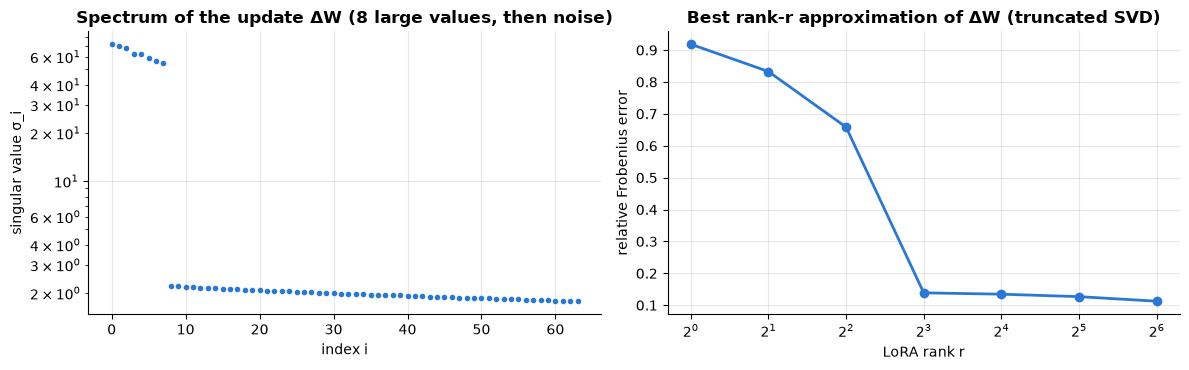

 rank r  parameters r(d+k) % of full d·k relative error
      1               1024          0.4%          0.918
      2               2048          0.8%          0.833
      4               4096          1.6%          0.658
      8               8192          3.1%          0.139
     16              16384          6.2%          0.135
     32              32768         12.5%          0.127
     64              65536         25.0%          0.113


In [18]:
d_l, k_l = 512, 512
B_true = rng.normal(size=(d_l, 8)); A_true = rng.normal(size=(8, k_l))
delta_W = B_true @ A_true / 8 + 0.05 * rng.normal(size=(d_l, k_l))   # "fine-tuning update": rank 8 + noise
U_l, s_l, Vt_l = np.linalg.svd(delta_W, full_matrices=False)
ranks = [1, 2, 4, 8, 16, 32, 64]
rel_err = [np.linalg.norm(delta_W - (U_l[:, :r] * s_l[:r]) @ Vt_l[:r], "fro") / np.linalg.norm(delta_W, "fro") for r in ranks]
params = [r * (d_l + k_l) for r in ranks]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].semilogy(s_l[:64], "o", ms=3); axes[0].set_xlabel("index i"); axes[0].set_ylabel("singular value σ_i")
axes[0].set_title("Spectrum of the update ΔW (8 large values, then noise)")
axes[1].plot(ranks, rel_err, "o-"); axes[1].set_xscale("log", base=2)
axes[1].set_xlabel("LoRA rank r"); axes[1].set_ylabel("relative Frobenius error")
axes[1].set_title("Best rank-r approximation of ΔW (truncated SVD)")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"rank r": ranks, "parameters r(d+k)": params,
                    "% of full d·k": [f"{100 * p / (d_l * k_l):.1f}%" for p in params],
                    "relative error": [f"{e:.3f}" for e in rel_err]}).to_string(index=False))

**What just happened?** The update has 8 large singular values followed by a noise floor. A rank-8 factorisation, with about 3% of the parameters of the full $512 \times 512$ matrix, drops the relative error from 0.66 (rank 4) to about 0.14, which is the noise floor: all of the low-rank signal is captured. Beyond rank 8, extra rank only fits noise, so the error falls very slowly (0.11 at rank 64). Real fine-tuning updates are not exactly low rank, but their spectra decay quickly enough that ranks of 8 to 64 work well in practice.

**4. More connections.**
- **PCA and embeddings:** PCA is a truncated SVD; scikit-learn's `PCA(svd_solver="randomized")` uses the algorithm above.
- **Recommender systems:** matrix factorisation of a sparse user-item matrix (CSR), solved by alternating least squares (many small Cholesky solves).
- **Second-order optimisation:** Hessian-free / Newton-CG methods solve $Hd = -g$ with CG using only Hessian-vector products (see [`11_matrix_calculus_and_autodiff_from_scratch.ipynb`](11_matrix_calculus_and_autodiff_from_scratch.ipynb)).
- **Graph ML:** PageRank, spectral clustering and graph convolutional networks all work with sparse adjacency or Laplacian matrices ([`05_Deep_Learning/07_gnn.ipynb`](../05_Deep_Learning/07_gnn.ipynb)).

---
## 11. Recap

- **LU with partial pivoting** ($PA = LU$, $\tfrac23 n^3$ flops) is what `solve` does; factor once and reuse for many right-hand sides; never form $A^{-1}$.
- **Cholesky** ($A = LL^\top$, $\tfrac13 n^3$) is for SPD matrices, doubles as a positive-definiteness test, and may need a small **jitter** for kernel matrices.
- **Householder QR** is stable; Gram–Schmidt loses orthogonality (classical like $\kappa^2\varepsilon$, modified like $\kappa\varepsilon$). The **normal equations square** $\kappa$.
- **Forward error ≲ κ × backward error**: expect to lose about $\log_{10}\kappa$ digits, even with a backward-stable algorithm.
- **CG** solves SPD systems with only matrix-vector products in $O(\sqrt\kappa)$ iterations; **preconditioning** reduces $\kappa$. Jacobi and Gauss–Seidel are simple but slow.
- **Power iteration** converges at rate $|\lambda_2/\lambda_1|$; inverse iteration targets a shift; RQI converges cubically; **PageRank** is power iteration on the Google matrix.
- **CSR** stores `data`, `indices`, `indptr`; memory and matvec are $O(\text{nnz})$.
- **Randomized SVD** and **sketching** trade a little accuracy for large savings; power iterations help when singular values decay slowly.
- In AI: ridge regression, GP inference (Cholesky, $O(n^3)$), PCA, recommenders and **LoRA** (low rank, Eckart–Young) all rest on these algorithms.

---
## Practice problems

**1. (Easy, conceptual)** You must solve $Ax = b_j$ for 1,000 different right-hand sides with the same $1000 \times 1000$ matrix. Estimate the flop counts of (a) calling `solve` 1,000 times and (b) one LU plus 1,000 triangular solve pairs.

<details><summary>Show solution</summary>

(a) Each `solve` refactors: $1000 \times \tfrac23 (1000)^3 \approx 6.7 \times 10^{11}$ flops. (b) One factorisation $\tfrac23 \times 10^9 \approx 6.7 \times 10^8$ plus $1000 \times 2 \times 10^6 = 2 \times 10^9$ for the solves, about $2.7 \times 10^9$ in total: roughly **250 times fewer** flops. (Passing all right-hand sides at once as a matrix, `solve(A, B)`, also factors only once.)

</details>

**2. (Easy)** Compute the Cholesky factor of $\begin{pmatrix} 4 & 2 \\ 2 & 3 \end{pmatrix}$ by hand and use it to solve $Ax = (2, 1)^\top$.

<details><summary>Show solution</summary>

```python
import numpy as np, math
A = np.array([[4., 2], [2, 3]])
L = np.array([[2., 0], [1, math.sqrt(2)]])
assert np.allclose(L @ L.T, A) and np.allclose(L, np.linalg.cholesky(A))
# Solve A x = [2, 1] with the factor: L y = b, then L^T x = y
b = np.array([2., 1])
y = np.array([b[0] / 2, (b[1] - 1 * (b[0] / 2)) / math.sqrt(2)])
x = np.array([(y[0] - 1 * (y[1] / math.sqrt(2))) / 2, y[1] / math.sqrt(2)])
print(L, x, np.linalg.solve(A, b))
assert np.allclose(x, np.linalg.solve(A, b))
```
$L_{11} = \sqrt4 = 2$, $L_{21} = 2/2 = 1$, $L_{22} = \sqrt{3 - 1^2} = \sqrt2$. Forward substitution gives $y = (1, 0)$, back substitution gives $x = (0.5, 0)$.

</details>

**3. (Medium)** Prove that $\kappa_2(A^\top A) = \kappa_2(A)^2$ and confirm numerically.

<details><summary>Show solution</summary>

```python
import numpy as np
rng = np.random.default_rng(0)
A = rng.normal(size=(100, 10)) @ np.diag(np.logspace(0, -4, 10))
s = np.linalg.svd(A, compute_uv=False)
print(np.linalg.cond(A) ** 2, np.linalg.cond(A.T @ A))
assert np.isclose(np.linalg.cond(A.T @ A), np.linalg.cond(A) ** 2, rtol=1e-3)
```
If $A = U\Sigma V^\top$, then $A^\top A = V\Sigma^\top U^\top U\Sigma V^\top = V\Sigma^2V^\top$: an eigendecomposition with eigenvalues $\sigma_i^2$. So $\kappa(A^\top A) = \sigma_{\max}^2/\sigma_{\min}^2 = \kappa(A)^2$.

</details>

**4. (Medium, coding)** Turn Gauss–Seidel into **SOR** (successive over-relaxation) with parameter $\omega$ and compare iteration counts for $\omega = 1, 1.5$ and the optimal $\omega$ on the 1-D Poisson matrix with $n = 30$.

<details><summary>Show solution</summary>

```python
import numpy as np
def sor(A, b, omega, tol=1e-8, max_iter=20_000):
    x = np.zeros_like(b)
    for k in range(1, max_iter + 1):
        for i in range(len(b)):
            gs = (b[i] - A[i, :i] @ x[:i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
            x[i] = (1 - omega) * x[i] + omega * gs          # omega = 1 is Gauss-Seidel
        if np.linalg.norm(b - A @ x) / np.linalg.norm(b) < tol:
            return x, k
    return x, max_iter

n = 30
T = 2 * np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1); b = np.ones(n)
omega_opt = 2 / (1 + np.sin(np.pi / (n + 1)))               # optimal for this matrix
for om in [1.0, 1.5, omega_opt]:
    x, k = sor(T, b, om)
    assert np.allclose(x, np.linalg.solve(T, b), atol=1e-5)
    print(f"omega = {om:.3f}: {k} iterations")
```
Over-relaxation ($\omega > 1$) extrapolates each Gauss–Seidel update. For the Poisson matrix the optimal $\omega = 2/(1 + \sin\frac{\pi}{n+1})$ cuts the iteration count from $O(n^2)$ to $O(n)$; on this $n = 30$ example it needs 115 iterations against 1,783 for Gauss–Seidel (585 with $\omega = 1.5$), about 15 times fewer.

</details>

**5. (Medium)** What goes wrong with power iteration on $\operatorname{diag}(1, -1, 0.5)$? How would you fix it?

<details><summary>Show solution</summary>

```python
import numpy as np
A = np.diag([1.0, -1.0, 0.5])            # |lambda_1| = |lambda_2| = 1
v = np.array([1.0, 1.0, 1.0])
for k in range(6):
    v = A @ v; v /= np.linalg.norm(v)
    print(k, np.round(v, 3))             # flips between (a, -a, .) and (a, a, .): never settles
```
Power iteration needs a **strict** gap $|\lambda_1| > |\lambda_2|$. With $\lambda = \pm1$ the components along both eigenvectors keep the same size and the sign of one flips every step, so $v_k$ alternates between two directions. (The eigenvalue 0.5 component dies out.) Fixes: shift the matrix ($A + cI$ changes $\pm 1$ to $1 + c$ and $c - 1$, which have different magnitudes), or use a block/subspace method.

</details>

**6. (Hard, coding)** Using only a matrix's CSR arrays, compute $A^\top x$ (without building the transpose). Test against SciPy.

<details><summary>Show solution</summary>

```python
import numpy as np, scipy.sparse as sp
def csr_rmatvec(data, indices, indptr, x, n_cols):
    """y = A^T x using A's CSR arrays: scatter each row's contribution."""
    y = np.zeros(n_cols)
    for i in range(len(indptr) - 1):
        start, end = indptr[i], indptr[i + 1]
        y[indices[start:end]] += data[start:end] * x[i]
    return y

rng = np.random.default_rng(1)
M = sp.random(50, 30, density=0.1, random_state=1, format="csr")
x = rng.normal(size=50)
assert np.allclose(csr_rmatvec(M.data, M.indices, M.indptr, x, 30), M.T @ x)
print("A^T x from CSR arrays is correct")
```
The CSR arrays of $A$ are the CSC arrays of $A^\top$, so $A^\top x$ is a "scatter" loop: still $O(\text{nnz})$, but writes go to scattered positions of $y$ (harder to parallelise than the row-wise "gather" of $Ax$).

</details>

**7. (Hard)** Verify the Eckart–Young theorem numerically: the rank-$k$ truncated SVD has spectral error $\sigma_{k+1}$ and Frobenius error $\sqrt{\sum_{i>k}\sigma_i^2}$, and another rank-$k$ approximation does no better.

<details><summary>Show solution</summary>

```python
import numpy as np
rng = np.random.default_rng(2)
A = rng.normal(size=(60, 40))
U, s, Vt = np.linalg.svd(A, full_matrices=False)
for k in [1, 5, 20]:
    Ak = (U[:, :k] * s[:k]) @ Vt[:k]
    spec, fro = np.linalg.norm(A - Ak, 2), np.linalg.norm(A - Ak, "fro")
    assert np.isclose(spec, s[k]) and np.isclose(fro, np.sqrt((s[k:] ** 2).sum()))
    # any other rank-k matrix does worse, e.g. a random rank-k projection of A
    Q, _ = np.linalg.qr(rng.normal(size=(60, k)))
    assert np.linalg.norm(A - Q @ (Q.T @ A), 2) >= spec - 1e-12
    print(k, round(spec, 4), round(s[k], 4))
```
Eckart–Young–Mirsky: the truncated SVD $A_k$ is the best rank-$k$ approximation in both the spectral norm (error $\sigma_{k+1}$) and the Frobenius norm (error $\sqrt{\sum_{i>k}\sigma_i^2}$).

</details>

---
## Further reading
- Lloyd N. Trefethen and David Bau III, *Numerical Linear Algebra* (SIAM; 25th-anniversary edition 2022): Lectures 4 to 5 (SVD), 7 to 11 (QR, least squares), 12 to 15 (conditioning and stability), 20 to 23 (LU, pivoting, Cholesky), 24 to 31 (eigenvalues), 32 to 40 (iterative methods, CG, preconditioning).
- Gene Golub and Charles Van Loan, *Matrix Computations*, 4th ed. (Johns Hopkins, 2013): the reference for every algorithm here.
- Yousef Saad, *Iterative Methods for Sparse Linear Systems*, 2nd ed. (SIAM, 2003; free PDF from the author's website).
- Halko, Martinsson and Tropp, "Finding Structure with Randomness: Probabilistic Algorithms for Constructing Approximate Matrix Decompositions", *SIAM Review* 53(2), 2011.
- Free: Jonathan Shewchuk, "An Introduction to the Conjugate Gradient Method Without the Agonizing Pain" (1994), and the fast.ai *Computational Linear Algebra* course notebooks.

## Next notebook
Continue with [`11_matrix_calculus_and_autodiff_from_scratch.ipynb`](11_matrix_calculus_and_autodiff_from_scratch.ipynb): gradients of matrix expressions and a reverse-mode autodiff engine built from scratch.